# Elección de K con K-Means


## 0. Preparar scikit-learn


In [1]:
%pip install scikit-learn --disable-pip-version-check


Note: you may need to restart the kernel to use updated packages.


## 1. Importar las librerías


In [2]:
import os
import json
import csv
import random
import time
import gc
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, pairwise_distances
from threadpoolctl import threadpool_limits

%matplotlib inline


## 2. Configuración


In [3]:
carpeta_tratada = r"C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\dataset ya tratado"
carpeta_trabajo = os.path.dirname(carpeta_tratada)
carpeta_resultados = os.path.join(carpeta_trabajo, "resultados eleccion k")
carpeta_modelos = os.path.join(carpeta_resultados, "modelos")
ruta_division = os.path.join(carpeta_trabajo, "division_fotos.json")

cantidad_imagenes = 45000
tamano_imagen = 128
semilla = 42
fotos_para_prueba = 20

ks_a_probar = list(range(1, 11))
ks_a_probar = sorted(set(ks_a_probar))
tamano_silueta = 5000
tamano_confirmacion = 10000
n_init = 3
max_iter = 200
hilos = 4

if not os.path.isdir(carpeta_tratada):
    raise ValueError("Primero debe existir la carpeta dataset ya tratado.")

os.makedirs(carpeta_modelos, exist_ok=True)
print("Dataset:", carpeta_tratada)
print("Resultados:", carpeta_resultados)
print("K a comparar:", ks_a_probar)


Dataset: C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\dataset ya tratado
Resultados: C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\resultados eleccion k
K a comparar: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


## 3. Separar las fotos de origen


In [4]:
fotos_origen = sorted([
    nombre for nombre in os.listdir(carpeta_tratada)
    if os.path.isdir(os.path.join(carpeta_tratada, nombre))
])

division_actualizada = False
if os.path.isfile(ruta_division):
    with open(ruta_division, encoding="utf-8") as archivo:
        division = json.load(archivo)
    if "validacion" in division:
        division["entrenamiento"] = sorted(division["entrenamiento"] + division.pop("validacion"))
        division_actualizada = True
    print("Separacion recuperada del archivo guardado.")
else:
    if len(fotos_origen) <= fotos_para_prueba:
        raise ValueError("No hay suficientes fotos de origen para esta separacion.")

    fotos_mezcladas = fotos_origen.copy()
    random.Random(semilla).shuffle(fotos_mezcladas)
    division = {
        "semilla": semilla,
        "prueba": sorted(fotos_mezcladas[:fotos_para_prueba]),
        "entrenamiento": sorted(fotos_mezcladas[fotos_para_prueba:]),
    }

    with open(ruta_division, "x", encoding="utf-8") as archivo:
        json.dump(division, archivo, ensure_ascii=False, indent=2)
    print("Separacion guardada.")

todas_las_fotos = division["entrenamiento"] + division["prueba"]
if set(todas_las_fotos) != set(fotos_origen) or len(todas_las_fotos) != len(set(todas_las_fotos)):
    raise ValueError("Las fotos cambiaron o la separacion no es valida. Revisa division_fotos.json.")

if division_actualizada:
    with open(ruta_division, "w", encoding="utf-8") as archivo:
        json.dump(division, archivo, ensure_ascii=False, indent=2)
    print("Separacion actualizada: solo entrenamiento y prueba.")

print("Fotos de entrenamiento:", len(division["entrenamiento"]))
print("Fotos de prueba:", len(division["prueba"]))


Separacion recuperada del archivo guardado.
Fotos de entrenamiento: 157
Fotos de prueba: 20


## 4. Seleccionar las 45.000 imágenes de entrenamiento


In [5]:
archivos_entrenamiento = []
for origen in division["entrenamiento"]:
    carpeta_origen = os.path.join(carpeta_tratada, origen)
    for nombre in sorted(os.listdir(carpeta_origen)):
        if nombre.lower().endswith(".png"):
            archivos_entrenamiento.append(f"{origen}/{nombre}")

if len(archivos_entrenamiento) < cantidad_imagenes:
    raise ValueError("Hay menos recortes de entrenamiento que la cantidad solicitada.")

muestra_relativa = random.Random(semilla).sample(archivos_entrenamiento, cantidad_imagenes)
ruta_muestra = os.path.join(carpeta_resultados, "muestra_entrenamiento.json")

if os.path.isfile(ruta_muestra):
    with open(ruta_muestra, encoding="utf-8") as archivo:
        muestra_guardada = json.load(archivo)
    if muestra_guardada != muestra_relativa:
        raise ValueError("La muestra cambio. Usa otra carpeta de resultados para este experimento.")
else:
    with open(ruta_muestra, "x", encoding="utf-8") as archivo:
        json.dump(muestra_relativa, archivo, ensure_ascii=False, indent=2)

archivos_muestra = [os.path.join(carpeta_tratada, nombre) for nombre in muestra_relativa]
huella_muestra = hashlib.sha256("\n".join(muestra_relativa).encode("utf-8")).hexdigest()
configuracion_modelos = {
    "cantidad_imagenes": cantidad_imagenes,
    "tamano_imagen": tamano_imagen,
    "canales": 3,
    "dtype": "float32",
    "escala": "0 a 1",
    "semilla": semilla,
    "n_init": n_init,
    "max_iter": max_iter,
    "algoritmo": "lloyd",
    "huella_muestra": huella_muestra,
}
ruta_configuracion = os.path.join(carpeta_resultados, "configuracion_modelos.json")
if os.path.isfile(ruta_configuracion):
    with open(ruta_configuracion, encoding="utf-8") as archivo:
        configuracion_guardada = json.load(archivo)
    if configuracion_guardada != configuracion_modelos:
        raise ValueError("La configuracion cambio. Usa otra carpeta de resultados.")
else:
    with open(ruta_configuracion, "x", encoding="utf-8") as archivo:
        json.dump(configuracion_modelos, archivo, ensure_ascii=False, indent=2)

if any(k < 1 or k >= cantidad_imagenes for k in ks_a_probar):
    raise ValueError("Cada K debe ser positiva y menor que la cantidad de imagenes.")
print("Recortes disponibles para entrenar:", len(archivos_entrenamiento))
print("Recortes seleccionados:", len(archivos_muestra))
print("La muestra utiliza solo fotos de entrenamiento.")


Recortes disponibles para entrenar: 157000
Recortes seleccionados: 45000
La muestra utiliza solo fotos de entrenamiento.


## 5. Cargar RGB, normalizar y aplanar


In [6]:
caracteristicas = tamano_imagen * tamano_imagen * 3
X = np.empty((cantidad_imagenes, caracteristicas), dtype=np.float32)

for posicion, ruta in enumerate(archivos_muestra):
    with Image.open(ruta) as foto:
        if foto.size != (tamano_imagen, tamano_imagen):
            raise ValueError(f"La imagen no mide 128 x 128: {ruta}")
        X[posicion] = np.asarray(foto.convert("RGB"), dtype=np.float32).reshape(-1)

    X[posicion] /= 255.0
    if (posicion + 1) % 1000 == 0:
        print(f"Cargadas {posicion + 1}/{cantidad_imagenes}", flush=True)

print("Forma de X:", X.shape)
print("Tipo:", X.dtype)
print("GB de la matriz X:", round(X.nbytes / 1_000_000_000, 2))
print("Rango de la primera imagen:", X[0].min(), X[0].max())


Cargadas 1000/45000
Cargadas 2000/45000
Cargadas 3000/45000
Cargadas 4000/45000
Cargadas 5000/45000
Cargadas 6000/45000
Cargadas 7000/45000
Cargadas 8000/45000
Cargadas 9000/45000
Cargadas 10000/45000
Cargadas 11000/45000
Cargadas 12000/45000
Cargadas 13000/45000
Cargadas 14000/45000
Cargadas 15000/45000
Cargadas 16000/45000
Cargadas 17000/45000
Cargadas 18000/45000
Cargadas 19000/45000
Cargadas 20000/45000
Cargadas 21000/45000
Cargadas 22000/45000
Cargadas 23000/45000
Cargadas 24000/45000
Cargadas 25000/45000
Cargadas 26000/45000
Cargadas 27000/45000
Cargadas 28000/45000
Cargadas 29000/45000
Cargadas 30000/45000
Cargadas 31000/45000
Cargadas 32000/45000
Cargadas 33000/45000
Cargadas 34000/45000
Cargadas 35000/45000
Cargadas 36000/45000
Cargadas 37000/45000
Cargadas 38000/45000
Cargadas 39000/45000
Cargadas 40000/45000
Cargadas 41000/45000
Cargadas 42000/45000
Cargadas 43000/45000
Cargadas 44000/45000
Cargadas 45000/45000
Forma de X: (45000, 49152)
Tipo: float32
GB de la matriz X: 8.85

## 6. Preparar la muestra inicial de silueta


In [7]:
generador = np.random.default_rng(semilla + 1)
indices_silueta = generador.choice(
    cantidad_imagenes, size=min(tamano_silueta, cantidad_imagenes), replace=False
)

print("Calculando distancias para la silueta...", flush=True)
X_silueta = X[indices_silueta]
with threadpool_limits(limits=hilos):
    distancias_silueta = pairwise_distances(X_silueta, metric="euclidean", n_jobs=1)
np.fill_diagonal(distancias_silueta, 0)
X_silueta = None
gc.collect()

print("Imagenes de la muestra de silueta:", len(indices_silueta))
print("MB de la matriz de distancias:", round(distancias_silueta.nbytes / 1_000_000, 1))


Calculando distancias para la silueta...
Imagenes de la muestra de silueta: 5000
MB de la matriz de distancias: 100.0


## 7. Entrenar un K-Means por cada K


In [8]:
resultados = []
ruta_tabla = os.path.join(carpeta_resultados, "comparacion_k.csv")

for k in ks_a_probar:
    ruta_modelo = os.path.join(carpeta_modelos, f"kmeans_{k:03d}.npz")

    if os.path.isfile(ruta_modelo):
        with np.load(ruta_modelo, allow_pickle=False) as datos:
            etiquetas = datos["etiquetas"]
            inercia = float(datos["inercia"])
            segundos = float(datos["segundos"])
            iteraciones = int(datos["iteraciones"])
        print(f"K={k}: ajuste recuperado", flush=True)
    else:
        print(f"Entrenando K={k} con {len(X)} imagenes...", flush=True)
        inicio = time.perf_counter()
        with threadpool_limits(limits=hilos):
            modelo = KMeans(
                n_clusters=k, init="k-means++", n_init=n_init,
                max_iter=max_iter, algorithm="lloyd",
                random_state=semilla, copy_x=False
            ).fit(X)

        segundos = time.perf_counter() - inicio
        etiquetas = modelo.labels_
        inercia = float(modelo.inertia_)
        iteraciones = int(modelo.n_iter_)

        ruta_temporal = ruta_modelo + ".tmp.npz"
        np.savez_compressed(
            ruta_temporal, etiquetas=etiquetas,
            centroides=modelo.cluster_centers_, inercia=inercia,
            segundos=segundos, iteraciones=iteraciones
        )
        os.replace(ruta_temporal, ruta_modelo)
        modelo = None
        gc.collect()

    etiquetas_muestra = etiquetas[indices_silueta]
    grupos_presentes = len(np.unique(etiquetas_muestra))
    silueta = float("nan")
    if 2 <= grupos_presentes < len(indices_silueta):
        with threadpool_limits(limits=hilos):
            silueta = silhouette_score(
                distancias_silueta, etiquetas_muestra, metric="precomputed"
            )

    resultados.append({
        "k": k, "inercia": inercia, "silueta": silueta,
        "grupos_en_silueta": grupos_presentes,
        "iteraciones": iteraciones, "segundos_entrenamiento": segundos,
    })

    with open(ruta_tabla, "w", newline="", encoding="utf-8") as archivo:
        escritor = csv.DictWriter(archivo, fieldnames=list(resultados[0]))
        escritor.writeheader()
        escritor.writerows(resultados)

    print(f"K={k} | inercia={inercia:.1f} | silueta={silueta:.4f} | segundos={segundos:.1f}", flush=True)
    if iteraciones >= max_iter:
        print("Este ajuste llego al limite de iteraciones; revisa su convergencia.", flush=True)

opciones_validas = [fila for fila in resultados if np.isfinite(fila["silueta"])]
if not opciones_validas:
    raise ValueError("No se pudo calcular silueta. Revisa los grupos y las muestras.")

mejor_fila = max(opciones_validas, key=lambda fila: fila["silueta"])
k_mejor_silueta = mejor_fila["k"]
print("\nMayor silueta inicial entre las K probadas:", k_mejor_silueta)
print("Tabla guardada en:", ruta_tabla)


K=1: ajuste recuperado
K=1 | inercia=166022160.0 | silueta=nan | segundos=137.8


K=2: ajuste recuperado
K=2 | inercia=125662000.0 | silueta=0.2157 | segundos=157.6
K=3: ajuste recuperado
K=3 | inercia=115317328.0 | silueta=0.1290 | segundos=203.5
K=4: ajuste recuperado
K=4 | inercia=111106296.0 | silueta=0.0814 | segundos=248.4
K=5: ajuste recuperado
K=5 | inercia=108952496.0 | silueta=0.0704 | segundos=304.8
K=6: ajuste recuperado
K=6 | inercia=106936704.0 | silueta=0.0548 | segundos=310.6
K=7: ajuste recuperado
K=7 | inercia=105829640.0 | silueta=0.0405 | segundos=422.6
K=8: ajuste recuperado
K=8 | inercia=104845752.0 | silueta=0.0364 | segundos=398.7
K=9: ajuste recuperado
K=9 | inercia=104057640.0 | silueta=0.0378 | segundos=410.1
K=10: ajuste recuperado
K=10 | inercia=103333152.0 | silueta=0.0342 | segundos=470.2

Mayor silueta inicial entre las K probadas: 2
Tabla guardada en: C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\resultados eleccion k\comparacion_k.csv


## 8. Comparar el codo y la silueta


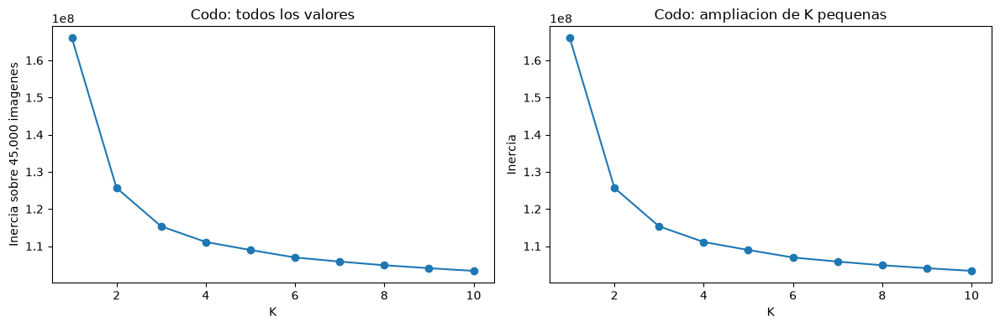

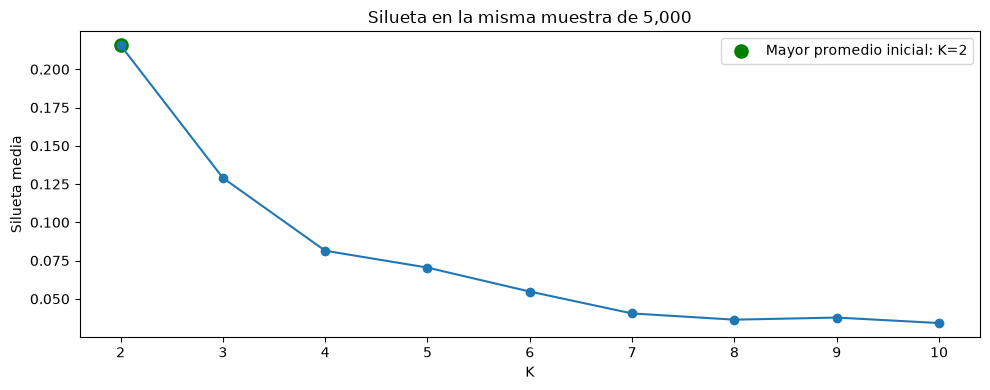

In [9]:
valores_k = [fila["k"] for fila in resultados]
inercias = [fila["inercia"] for fila in resultados]
siluetas = [fila["silueta"] for fila in resultados]

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(valores_k, inercias, "o-")
ejes[0].set(title="Codo: todos los valores", xlabel="K", ylabel=f"Inercia sobre {len(X):,} imagenes")

filas_pequenas = [fila for fila in resultados if fila["k"] <= 10]
ejes[1].plot(
    [fila["k"] for fila in filas_pequenas],
    [fila["inercia"] for fila in filas_pequenas], "o-"
)
ejes[1].set(title="Codo: ampliacion de K pequenas", xlabel="K", ylabel="Inercia")
plt.tight_layout()
fig.savefig(os.path.join(carpeta_resultados, "codo.png"), dpi=150)
plt.show()
plt.close(fig)

fig, eje = plt.subplots(figsize=(10, 4))
eje.plot(valores_k, siluetas, "o-")
eje.scatter(k_mejor_silueta, mejor_fila["silueta"], s=90, color="green",
            label=f"Mayor promedio inicial: K={k_mejor_silueta}")
eje.set(title=f"Silueta en la misma muestra de {len(indices_silueta):,}", xlabel="K", ylabel="Silueta media")
eje.legend()
plt.tight_layout()
fig.savefig(os.path.join(carpeta_resultados, "silueta_inicial.png"), dpi=150)
plt.show()
plt.close(fig)


## 9. Elegir las K que vamos a comprobar


In [10]:
ordenadas = sorted(opciones_validas, key=lambda fila: fila["silueta"], reverse=True)
ks_finalistas = sorted([fila["k"] for fila in ordenadas[:3]])


for k in ks_finalistas:
    if k not in ks_a_probar or k < 2:
        raise ValueError("Las finalistas deben ser K ya entrenadas, mayores que 1.")

print("K finalistas:", ks_finalistas)


K finalistas: [2, 3, 4]


## 10. Repetir con otra muestra y confirmar con 10.000


Preparando evaluacion con 5000 imagenes...
K=2 | muestra=5000 | silueta=0.2210 | grupos=2/2
K=3 | muestra=5000 | silueta=0.1354 | grupos=3/3
K=4 | muestra=5000 | silueta=0.0871 | grupos=4/4
Preparando evaluacion con 10000 imagenes...
K=2 | muestra=10000 | silueta=0.2174 | grupos=2/2
K=3 | muestra=10000 | silueta=0.1300 | grupos=3/3
K=4 | muestra=10000 | silueta=0.0829 | grupos=4/4

K | inicial 5000 | repeticion 5000 | confirmacion 10000
2 | 0.2157 | 0.2210 | 0.2174
3 | 0.1290 | 0.1354 | 0.1300
4 | 0.0814 | 0.0871 | 0.0829


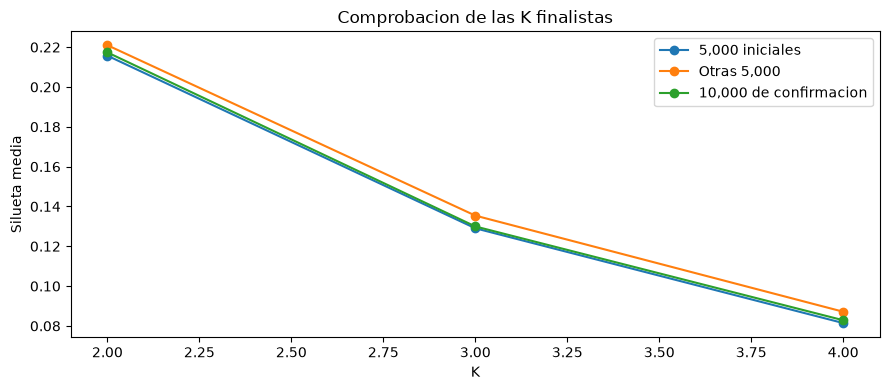

In [11]:
distancias_silueta = None
gc.collect()
confirmacion = {}
for k in ks_finalistas:
    inicial = next(fila["silueta"] for fila in resultados if fila["k"] == k)
    confirmacion[k] = {"k": k, "silueta_inicial": inicial}

muestras_a_evaluar = [
    (tamano_silueta, semilla + 2, "silueta_repeticion"),
    (tamano_confirmacion, semilla + 3, "silueta_confirmacion"),
]
ruta_confirmacion = os.path.join(carpeta_resultados, "confirmacion_k.csv")

for tamano, semilla_muestra, nombre_columna in muestras_a_evaluar:
    generador = np.random.default_rng(semilla_muestra)
    indices_evaluacion = generador.choice(
        cantidad_imagenes, size=min(tamano, cantidad_imagenes), replace=False
    )
    print(f"Preparando evaluacion con {len(indices_evaluacion)} imagenes...", flush=True)
    X_evaluacion = X[indices_evaluacion]
    with threadpool_limits(limits=hilos):
        distancias_evaluacion = pairwise_distances(X_evaluacion, metric="euclidean", n_jobs=1)
    np.fill_diagonal(distancias_evaluacion, 0)
    X_evaluacion = None
    gc.collect()

    for k in ks_finalistas:
        ruta_modelo = os.path.join(carpeta_modelos, f"kmeans_{k:03d}.npz")
        with np.load(ruta_modelo, allow_pickle=False) as datos:
            etiquetas_evaluacion = datos["etiquetas"][indices_evaluacion]

        grupos_presentes = len(np.unique(etiquetas_evaluacion))
        puntaje = float("nan")
        if 2 <= grupos_presentes < len(indices_evaluacion):
            with threadpool_limits(limits=hilos):
                puntaje = silhouette_score(
                    distancias_evaluacion, etiquetas_evaluacion, metric="precomputed"
                )

        confirmacion[k][nombre_columna] = puntaje
        confirmacion[k][nombre_columna + "_grupos"] = grupos_presentes
        print(f"K={k} | muestra={len(indices_evaluacion)} | silueta={puntaje:.4f} | grupos={grupos_presentes}/{k}", flush=True)

    distancias_evaluacion = None
    gc.collect()

filas_confirmacion = [confirmacion[k] for k in ks_finalistas]
with open(ruta_confirmacion, "w", newline="", encoding="utf-8") as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=list(filas_confirmacion[0]))
    escritor.writeheader()
    escritor.writerows(filas_confirmacion)

print(f"\nK | inicial {min(tamano_silueta, cantidad_imagenes)} | repeticion {min(tamano_silueta, cantidad_imagenes)} | confirmacion {min(tamano_confirmacion, cantidad_imagenes)}")
for fila in filas_confirmacion:
    print(f"{fila['k']} | {fila['silueta_inicial']:.4f} | {fila['silueta_repeticion']:.4f} | {fila['silueta_confirmacion']:.4f}")

fig, eje = plt.subplots(figsize=(9, 4))
for columna, nombre in [
    ("silueta_inicial", f"{min(tamano_silueta, cantidad_imagenes):,} iniciales"),
    ("silueta_repeticion", f"Otras {min(tamano_silueta, cantidad_imagenes):,}"),
    ("silueta_confirmacion", f"{min(tamano_confirmacion, cantidad_imagenes):,} de confirmacion"),
]:
    eje.plot(ks_finalistas, [confirmacion[k][columna] for k in ks_finalistas], "o-", label=nombre)
eje.set(title="Comprobacion de las K finalistas", xlabel="K", ylabel="Silueta media")
eje.legend()
plt.tight_layout()
fig.savefig(os.path.join(carpeta_resultados, "confirmacion_silueta.png"), dpi=150)
plt.show()
plt.close(fig)


## 11. Examinar ejemplos de un candidato


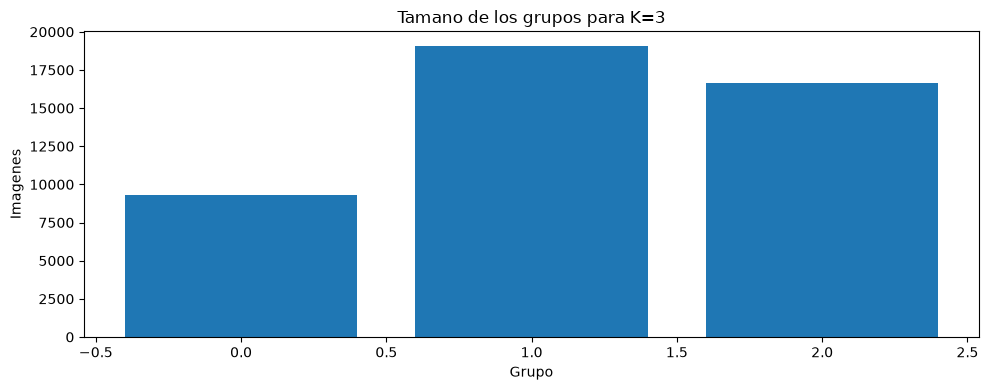

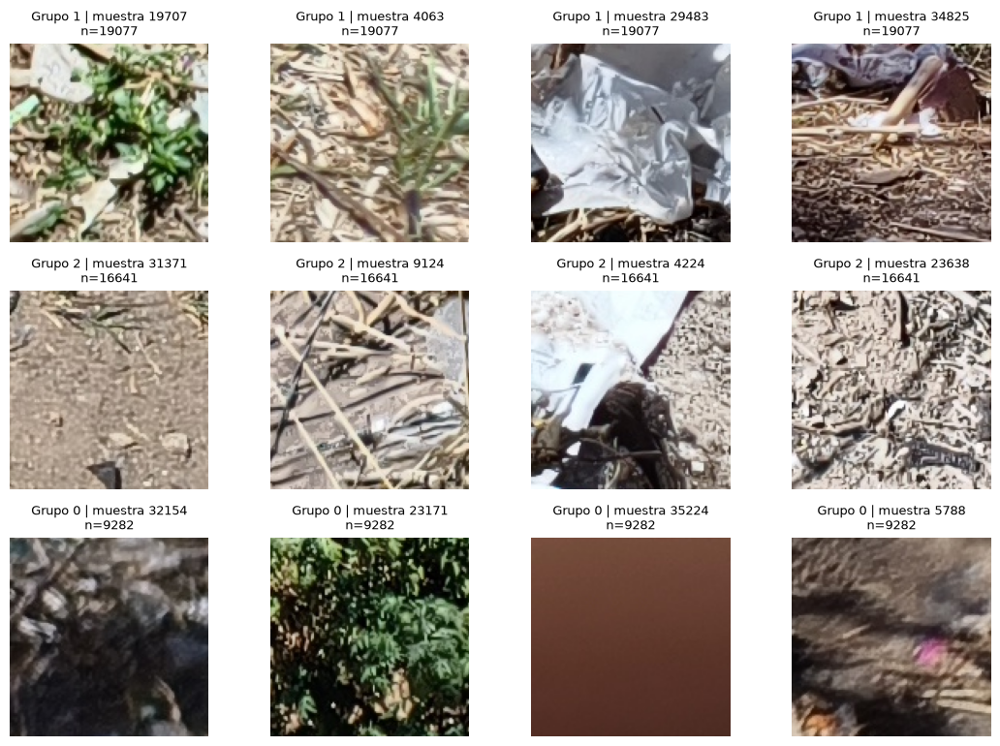

In [ ]:
k_inspeccion = 3
max_grupos_mostrar = 12
ejemplos_por_grupo = 4

ruta_modelo = os.path.join(carpeta_modelos, f"kmeans_{k_inspeccion:03d}.npz")
with np.load(ruta_modelo, allow_pickle=False) as datos:
    etiquetas_inspeccion = datos["etiquetas"]

conteos = np.bincount(etiquetas_inspeccion, minlength=k_inspeccion)
fig, eje = plt.subplots(figsize=(10, 4))
eje.bar(range(k_inspeccion), conteos)
eje.set(title=f"Tamano de los grupos para K={k_inspeccion}", xlabel="Grupo", ylabel="Imagenes")
plt.tight_layout()
plt.show()
plt.close(fig)

grupos_mostrar = np.argsort(-conteos)[:max_grupos_mostrar]
grupos_mostrar = [grupo for grupo in grupos_mostrar if conteos[grupo] > 0]
fig, ejes = plt.subplots(
    len(grupos_mostrar), ejemplos_por_grupo,
    figsize=(11, 2.6 * len(grupos_mostrar)), squeeze=False
)
for eje in ejes.flat:
    eje.axis("off")

generador = np.random.default_rng(semilla)
for fila, grupo in enumerate(grupos_mostrar):
    miembros = np.flatnonzero(etiquetas_inspeccion == grupo)
    posiciones = generador.choice(miembros, size=min(ejemplos_por_grupo, len(miembros)), replace=False)
    for eje, posicion in zip(ejes[fila], posiciones):
        with Image.open(archivos_muestra[posicion]) as foto:
            eje.imshow(foto)
        eje.set_title(f"Grupo {grupo} | muestra {posicion}\nn={conteos[grupo]}", fontsize=9)

plt.tight_layout()
fig.savefig(os.path.join(carpeta_resultados, f"ejemplos_k_{k_inspeccion:03d}.png"), dpi=150)
plt.show()
plt.close(fig)


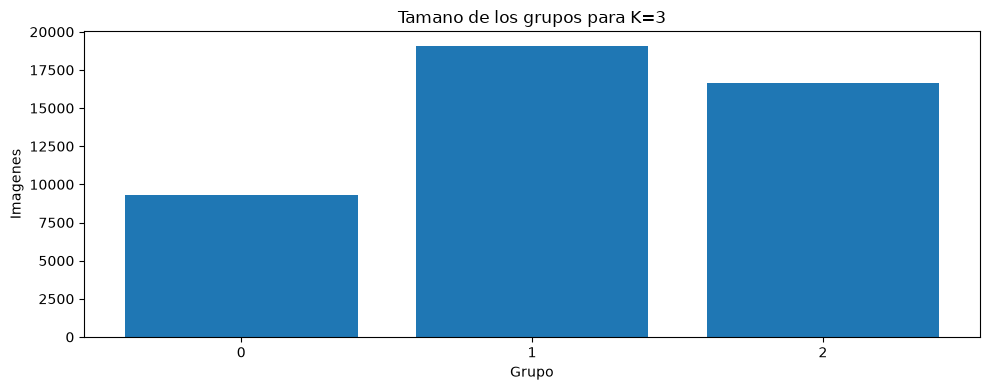

In [ ]:
k_barras = 3
ruta_modelo_barras = os.path.join(carpeta_modelos, f"kmeans_{k_barras:03d}.npz")
with np.load(ruta_modelo_barras, allow_pickle=False) as datos:
    etiquetas_barras = datos["etiquetas"]

conteos_barras = np.bincount(etiquetas_barras, minlength=k_barras)
fig, eje = plt.subplots(figsize=(10, 4))
eje.bar(range(k_barras), conteos_barras)
eje.set_xticks(range(k_barras))
eje.set(title=f"Tamano de los grupos para K={k_barras}", xlabel="Grupo", ylabel="Imagenes")
plt.tight_layout()
fig.savefig(os.path.join(carpeta_resultados, f"barras_k_{k_barras:03d}.png"), dpi=150)
plt.show()
plt.close(fig)


## 12. Guardar la K que tú decidas


In [ ]:
k_elegido = None
motivo_eleccion = ""

if k_elegido is None:
    print("Revisa los resultados y escribe tu K en k_elegido. Despues ejecuta esta celda.")
elif k_elegido not in [fila["k"] for fila in resultados]:
    raise ValueError("Elige una K que hayas entrenado y revisado.")
else:
    decision = {
        "k": int(k_elegido),
        "motivo": motivo_eleccion,
        "cantidad_imagenes": cantidad_imagenes,
        "tamano_imagen": tamano_imagen,
        "canales": 3,
        "normalizacion": "float32 dividido entre 255",
        "huella_muestra": huella_muestra,
        "archivo_division": os.path.relpath(ruta_division, carpeta_trabajo).replace(os.sep, "/"),
        "archivo_muestra": os.path.relpath(ruta_muestra, carpeta_trabajo).replace(os.sep, "/"),
    }
    ruta_decision = os.path.join(carpeta_resultados, "eleccion_k.json")
    with open(ruta_decision, "w", encoding="utf-8") as archivo:
        json.dump(decision, archivo, ensure_ascii=False, indent=2)
    print("K elegida:", k_elegido)
    print("Decision guardada en:", ruta_decision)


## 13. Prueba adicional con K=50


In [12]:
if "X" not in globals() or X is None:
    raise ValueError("Primero ejecuta las secciones 1 a 5 para cargar X.")
if X.shape != (45000, 49152):
    raise ValueError("Esta prueba necesita las 45.000 imagenes RGB de 128 x 128.")

k_prueba_50 = 50
ruta_modelo_50 = os.path.join(carpeta_modelos, "kmeans_050.npz")

if os.path.isfile(ruta_modelo_50):
    with np.load(ruta_modelo_50, allow_pickle=False) as datos_50:
        etiquetas_50 = datos_50["etiquetas"]
        inercia_50 = float(datos_50["inercia"])
        segundos_50 = float(datos_50["segundos"])
        iteraciones_50 = int(datos_50["iteraciones"])
    print("K=50: ajuste recuperado del archivo guardado.", flush=True)
else:
    print("Entrenando solamente K=50 con 45000 imagenes...", flush=True)
    inicio_50 = time.perf_counter()
    with threadpool_limits(limits=hilos):
        modelo_50 = KMeans(
            n_clusters=k_prueba_50, init="k-means++", n_init=n_init,
            max_iter=max_iter, algorithm="lloyd",
            random_state=semilla, copy_x=False
        ).fit(X)

    segundos_50 = time.perf_counter() - inicio_50
    etiquetas_50 = modelo_50.labels_
    inercia_50 = float(modelo_50.inertia_)
    iteraciones_50 = int(modelo_50.n_iter_)

    ruta_temporal_50 = ruta_modelo_50 + ".tmp.npz"
    np.savez_compressed(
        ruta_temporal_50, etiquetas=etiquetas_50,
        centroides=modelo_50.cluster_centers_, inercia=inercia_50,
        segundos=segundos_50, iteraciones=iteraciones_50
    )
    os.replace(ruta_temporal_50, ruta_modelo_50)
    modelo_50 = None
    gc.collect()

print("Inercia de K=50:", inercia_50)
print("Iteraciones:", iteraciones_50)
print("Minutos del entrenamiento guardado:", round(segundos_50 / 60, 2))
if iteraciones_50 >= max_iter:
    print("Este ajuste llego al limite de iteraciones; revisa su convergencia.")


Entrenando solamente K=50 con 45000 imagenes...
Inercia de K=50: 95710896.0
Iteraciones: 84
Minutos del entrenamiento guardado: 24.57


In [13]:
generador_silueta_50 = np.random.default_rng(semilla + 1)
indices_silueta_50 = generador_silueta_50.choice(
    len(X), size=min(tamano_silueta, len(X)), replace=False
)

print("Preparando la misma muestra inicial de silueta...", flush=True)
X_silueta_50 = X[indices_silueta_50]
with threadpool_limits(limits=hilos):
    distancias_50 = pairwise_distances(X_silueta_50, metric="euclidean", n_jobs=1)
np.fill_diagonal(distancias_50, 0)
X_silueta_50 = None
gc.collect()

etiquetas_silueta_50 = etiquetas_50[indices_silueta_50]
grupos_silueta_50 = len(np.unique(etiquetas_silueta_50))
silueta_50 = float("nan")
if 2 <= grupos_silueta_50 < len(indices_silueta_50):
    with threadpool_limits(limits=hilos):
        silueta_50 = silhouette_score(
            distancias_50, etiquetas_silueta_50, metric="precomputed"
        )
distancias_50 = None
gc.collect()

resultado_50 = {
    "k": k_prueba_50, "inercia": inercia_50, "silueta": silueta_50,
    "grupos_en_silueta": grupos_silueta_50,
    "iteraciones": iteraciones_50, "segundos_entrenamiento": segundos_50,
}

comparacion_con_50 = []
ruta_tabla_anterior_50 = os.path.join(carpeta_resultados, "comparacion_k.csv")
if os.path.isfile(ruta_tabla_anterior_50):
    with open(ruta_tabla_anterior_50, newline="", encoding="utf-8") as archivo:
        comparacion_con_50 = [fila for fila in csv.DictReader(archivo) if int(fila["k"]) != 50]
comparacion_con_50.append(resultado_50)
comparacion_con_50.sort(key=lambda fila: int(fila["k"]))

ruta_tabla_50 = os.path.join(carpeta_resultados, "comparacion_k_con_50.csv")
with open(ruta_tabla_50, "w", newline="", encoding="utf-8") as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=list(resultado_50))
    escritor.writeheader()
    escritor.writerows(comparacion_con_50)

print("K | Inercia | Silueta en la misma muestra inicial")
for fila in comparacion_con_50:
    if int(fila["k"]) in [2, 3, 4, 10, 50]:
        print(f"{int(fila['k'])} | {float(fila['inercia']):.1f} | {float(fila['silueta']):.4f}")
print(f"Grupos de K=50 presentes en la muestra: {grupos_silueta_50}/50")
if grupos_silueta_50 < k_prueba_50:
    print("La muestra no incluye todos los grupos; conviene ampliar la evaluacion.")
print("Comparacion guardada en:", ruta_tabla_50)


Preparando la misma muestra inicial de silueta...
K | Inercia | Silueta en la misma muestra inicial
2 | 125662000.0 | 0.2157
3 | 115317328.0 | 0.1290
4 | 111106296.0 | 0.0814
10 | 103333152.0 | 0.0342
50 | 95710896.0 | -0.0215
Grupos de K=50 presentes en la muestra: 47/50
La muestra no incluye todos los grupos; conviene ampliar la evaluacion.
Comparacion guardada en: C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\resultados eleccion k\comparacion_k_con_50.csv


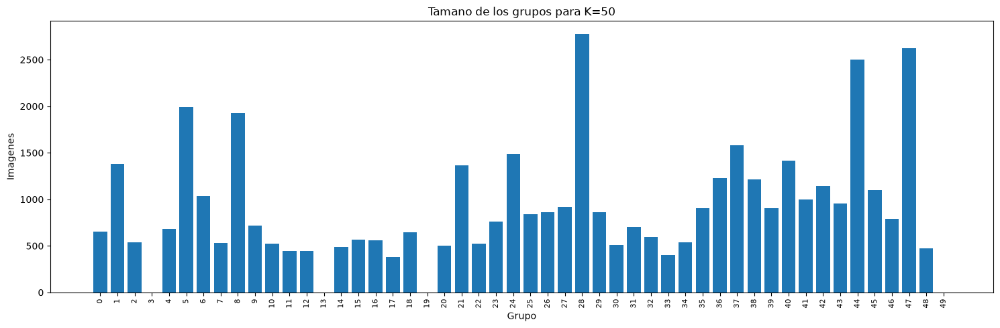

In [14]:
conteos_50 = np.bincount(etiquetas_50, minlength=k_prueba_50)
fig, eje = plt.subplots(figsize=(15, 5))
eje.bar(range(k_prueba_50), conteos_50)
eje.set_xticks(range(k_prueba_50))
eje.tick_params(axis="x", labelsize=8, rotation=90)
eje.set(title="Tamano de los grupos para K=50", xlabel="Grupo", ylabel="Imagenes")
plt.tight_layout()
fig.savefig(os.path.join(carpeta_resultados, "barras_k_050.png"), dpi=150)
plt.show()
plt.close(fig)


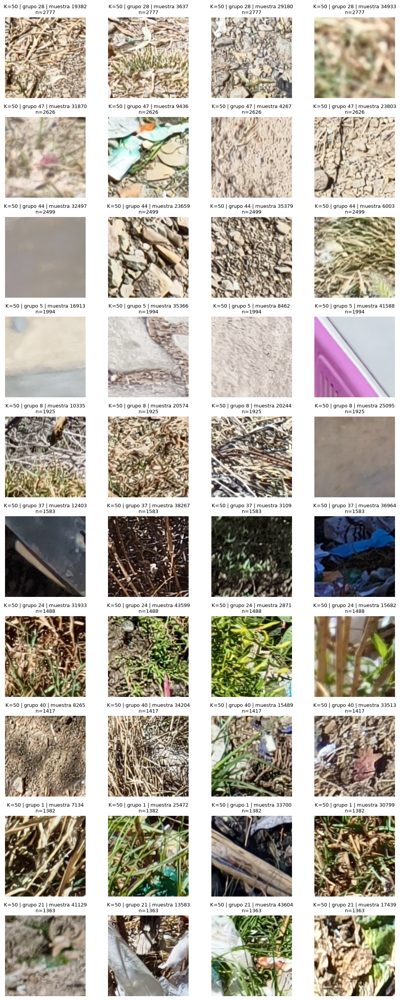

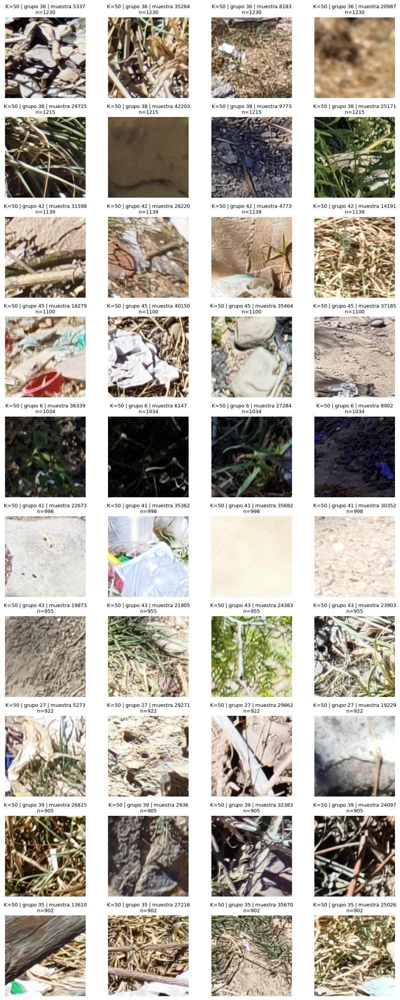

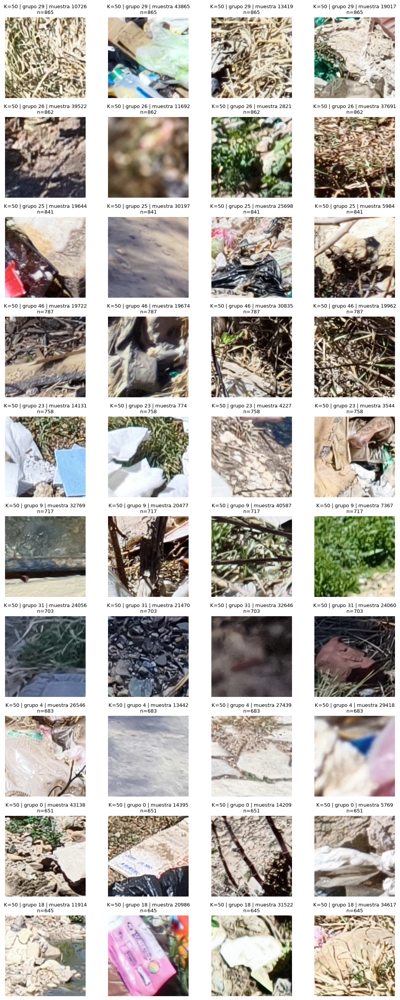

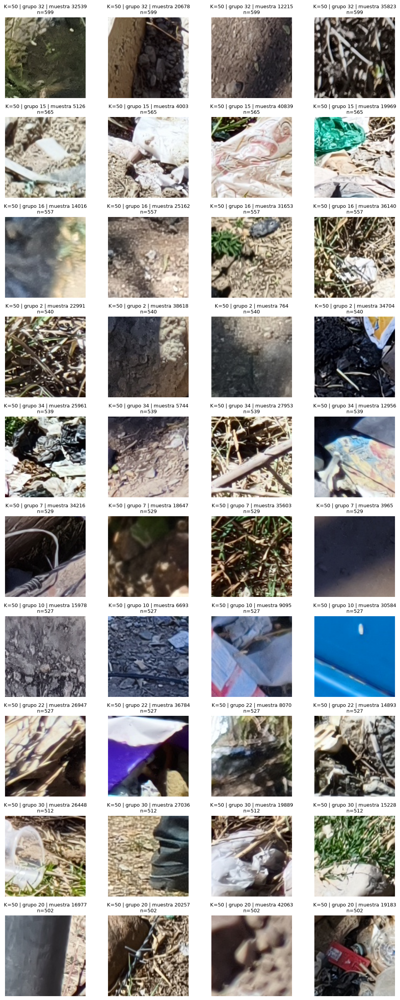

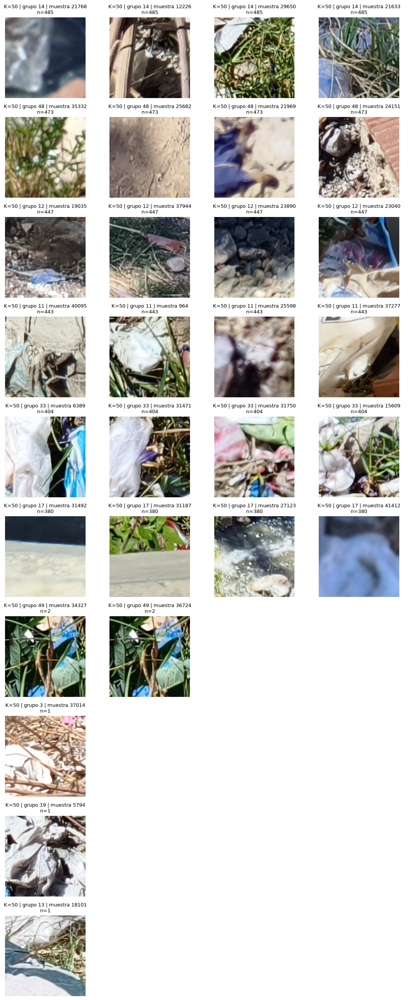

In [15]:
ejemplos_por_grupo_50 = 4
grupos_por_figura_50 = 10
generador_ejemplos_50 = np.random.default_rng(semilla)
grupos_50 = [grupo for grupo in np.argsort(-conteos_50) if conteos_50[grupo] > 0]

for inicio_50 in range(0, len(grupos_50), grupos_por_figura_50):
    grupos_pagina_50 = grupos_50[inicio_50:inicio_50 + grupos_por_figura_50]
    fig, ejes = plt.subplots(
        len(grupos_pagina_50), ejemplos_por_grupo_50,
        figsize=(11, 2.6 * len(grupos_pagina_50)), squeeze=False
    )
    for eje in ejes.flat:
        eje.axis("off")

    for fila, grupo in enumerate(grupos_pagina_50):
        miembros_50 = np.flatnonzero(etiquetas_50 == grupo)
        posiciones_50 = generador_ejemplos_50.choice(
            miembros_50, size=min(ejemplos_por_grupo_50, len(miembros_50)), replace=False
        )
        for eje, posicion in zip(ejes[fila], posiciones_50):
            with Image.open(archivos_muestra[posicion]) as foto:
                eje.imshow(foto)
            eje.set_title(f"K=50 | grupo {grupo} | muestra {posicion}\nn={conteos_50[grupo]}", fontsize=9)

    pagina_50 = inicio_50 // grupos_por_figura_50 + 1
    plt.tight_layout()
    fig.savefig(os.path.join(carpeta_resultados, f"ejemplos_k_050_pagina_{pagina_50}.png"), dpi=150)
    plt.show()
    plt.close(fig)


## 14. Curvas del codo y de Silueta incluyendo K=50


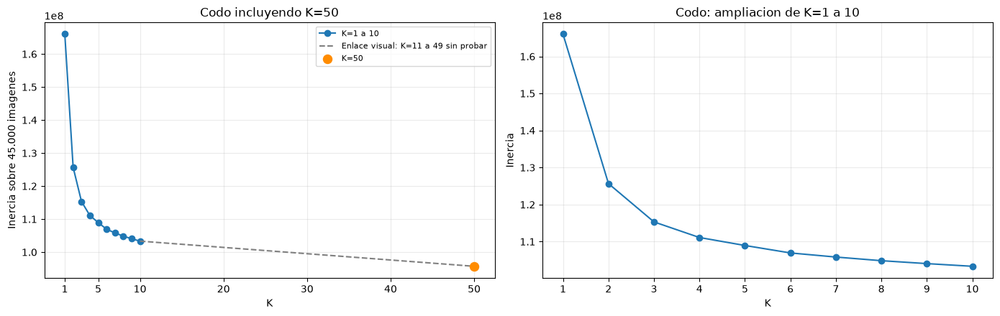

De K=10 a K=50, la inercia disminuyo 7.38%.


In [16]:
import csv
import os
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

carpeta_curvas_50 = r"C:\Users\PC\Desktop\SIS420(IA1)_ArapaENM_CICO\SegundoParcial\No supervisado\resultados eleccion k"
ruta_curvas_50 = os.path.join(carpeta_curvas_50, "comparacion_k_con_50.csv")
if not os.path.isfile(ruta_curvas_50):
    raise ValueError("Primero debe estar guardada la tabla de comparacion con K=50 de la seccion 13.")

filas_curvas_50 = []
with open(ruta_curvas_50, newline="", encoding="utf-8") as archivo:
    for fila in csv.DictReader(archivo):
        filas_curvas_50.append({
            "k": int(fila["k"]), "inercia": float(fila["inercia"]),
            "silueta": float(fila["silueta"]),
            "grupos_en_silueta": int(fila["grupos_en_silueta"]),
        })
filas_curvas_50.sort(key=lambda fila: fila["k"])

filas_base_50 = [fila for fila in filas_curvas_50 if fila["k"] <= 10]
filas_punto_50 = [fila for fila in filas_curvas_50 if fila["k"] == 50]
if not filas_base_50 or not filas_punto_50:
    raise ValueError("La tabla debe contener los resultados anteriores y el resultado de K=50.")
punto_curva_50 = filas_punto_50[0]
ultima_base_50 = filas_base_50[-1]
ks_base_50 = [fila["k"] for fila in filas_base_50]
inercias_base_50 = [fila["inercia"] for fila in filas_base_50]

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
ejes[0].plot(ks_base_50, inercias_base_50, "o-", label="K=1 a 10")
ejes[0].plot(
    [ultima_base_50["k"], 50],
    [ultima_base_50["inercia"], punto_curva_50["inercia"]],
    "--", color="gray", label="Enlace visual: K=11 a 49 sin probar"
)
ejes[0].scatter(50, punto_curva_50["inercia"], color="darkorange", s=75, zorder=3, label="K=50")
ejes[0].set(title="Codo incluyendo K=50", xlabel="K", ylabel="Inercia sobre 45.000 imagenes")
ejes[0].set_xticks([1, 5, 10, 20, 30, 40, 50])
ejes[0].legend(fontsize=8)

ejes[1].plot(ks_base_50, inercias_base_50, "o-")
ejes[1].set(title="Codo: ampliacion de K=1 a 10", xlabel="K", ylabel="Inercia")
ejes[1].set_xticks(ks_base_50)
for eje in ejes:
    eje.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(os.path.join(carpeta_curvas_50, "codo_con_k_50.png"), dpi=150)
plt.show()
plt.close(fig)

reduccion_inercia_50 = 100 * (ultima_base_50["inercia"] - punto_curva_50["inercia"]) / ultima_base_50["inercia"]
print(f"De K={ultima_base_50['k']} a K=50, la inercia disminuyo {reduccion_inercia_50:.2f}%.")


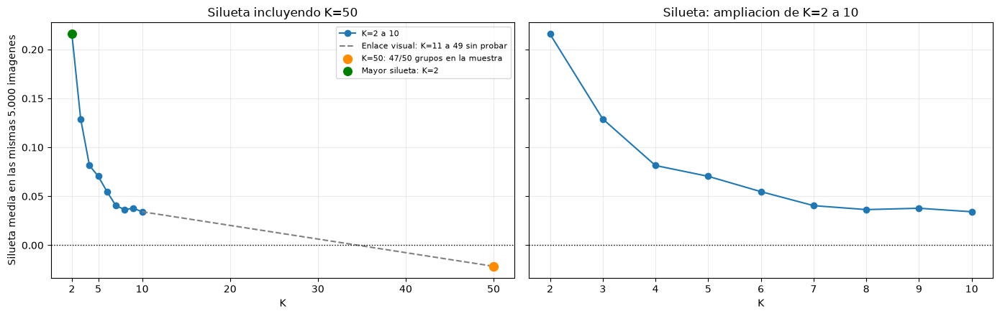

K | Inercia | Silueta inicial | Grupos presentes en la muestra
2 | 125662000.0 | 0.2157 | 2/2
3 | 115317328.0 | 0.1290 | 3/3
4 | 111106296.0 | 0.0814 | 4/4
10 | 103333152.0 | 0.0342 | 10/10
50 | 95710896.0 | -0.0215 | 47/50


In [17]:
filas_silueta_base_50 = [fila for fila in filas_base_50 if np.isfinite(fila["silueta"])]
ks_silueta_base_50 = [fila["k"] for fila in filas_silueta_base_50]
siluetas_base_50 = [fila["silueta"] for fila in filas_silueta_base_50]
mejor_curvas_50 = max(
    [fila for fila in filas_curvas_50 if np.isfinite(fila["silueta"])],
    key=lambda fila: fila["silueta"]
)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
ejes[0].plot(ks_silueta_base_50, siluetas_base_50, "o-", label="K=2 a 10")
ejes[0].plot(
    [ultima_base_50["k"], 50],
    [ultima_base_50["silueta"], punto_curva_50["silueta"]],
    "--", color="gray", label="Enlace visual: K=11 a 49 sin probar"
)
ejes[0].scatter(
    50, punto_curva_50["silueta"], color="darkorange", s=75, zorder=3,
    label=f"K=50: {punto_curva_50['grupos_en_silueta']}/50 grupos en la muestra"
)
ejes[0].scatter(
    mejor_curvas_50["k"], mejor_curvas_50["silueta"], color="green", s=70, zorder=4,
    label=f"Mayor silueta: K={mejor_curvas_50['k']}"
)
ejes[0].set(title="Silueta incluyendo K=50", xlabel="K", ylabel="Silueta media en las mismas 5.000 imagenes")
ejes[0].set_xticks([2, 5, 10, 20, 30, 40, 50])
ejes[0].legend(fontsize=8)

ejes[1].plot(ks_silueta_base_50, siluetas_base_50, "o-")
ejes[1].set(title="Silueta: ampliacion de K=2 a 10", xlabel="K")
ejes[1].set_xticks(ks_silueta_base_50)
for eje in ejes:
    eje.axhline(0, color="black", linestyle=":", linewidth=1)
    eje.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(os.path.join(carpeta_curvas_50, "silueta_con_k_50.png"), dpi=150)
plt.show()
plt.close(fig)

print("K | Inercia | Silueta inicial | Grupos presentes en la muestra")
for fila in filas_curvas_50:
    if fila["k"] in [2, 3, 4, 10, 50]:
        print(f"{fila['k']} | {fila['inercia']:.1f} | {fila['silueta']:.4f} | {fila['grupos_en_silueta']}/{fila['k']}")
